In [12]:
import torch
from torch import nn
import copy

In [2]:
w = torch.tensor(8.0,requires_grad=True)

In [3]:
loss = (w-5) ** 2

In [4]:
loss.backward()

In [6]:
print(w.item())
print(loss.item())
print(w.grad.item())


8.0
9.0
6.0


In [7]:
lr = 0.1

In [8]:
with torch.no_grad():
  w -= lr * w.grad

In [9]:
print(w.item())

7.400000095367432


In [10]:
new_loss = (w-5) ** 2

In [11]:
print(new_loss.item())

5.760000228881836


In [13]:
torch.manual_seed(42)

In [14]:
x = torch.linspace(-5,5,100).reshape(-1,1)
y = 2 * x + 1

In [15]:
model_sgd = nn.Linear(1,1)
model_adam = nn.Linear(1,1)

In [16]:
with torch.no_grad():
  model_sgd.weight.fill_(0.0)
  model_sgd.bias.fill_(0.0)

  model_adam.weight.fill_(0.0)
  model_adam.bias.fill_(0.0)

In [17]:
criterion = nn.MSELoss()

In [34]:
def train(model,optimier,epoches=100):
  losses = []
  for epoch in range(epoches):
    pred = model(x)
    loss = criterion(pred,y)

    optimier.zero_grad()
    loss.backward()
    optimier.step()

    losses.append(loss.item())

  return losses

In [19]:
lr_sgd = 0.1
lr_adam = 0.1

optimizer_sgd = torch.optim.SGD(model_sgd.parameters(),lr=lr_sgd)
optimizer_adam = torch.optim.Adam(model_adam.parameters(),lr=lr_adam)

In [20]:
print(f"sgd学习率:{lr_sgd}")
print(f"adam学习率:{lr_adam}")

sgd学习率:0.1
adam学习率:0.1


In [35]:
loss_history_sgd = train(model_sgd,optimizer_sgd,epoches=100)
loss_history_adam = train(model_adam,optimizer_adam,epoches=100)

In [36]:
w_sgd,b_sgd = model_sgd.weight.item(),model_sgd.bias.item()
w_adam,b_adam = model_adam.weight.item(),model_adam.bias.item()

In [37]:
print(w_sgd)
print(b_sgd)

1.9999998807907104
0.9999998211860657


In [38]:
print(w_adam)
print(b_adam)

1.9999430179595947
1.0000073909759521


In [39]:
for i in range(5):
    print(f"Epoch {i+1:02d} | SGD Loss: {loss_history_sgd[i]:.4f} | Adam Loss: {loss_history_adam[i]:.4f}")

Epoch 01 | SGD Loss: 0.0000 | Adam Loss: 0.0006
Epoch 02 | SGD Loss: 0.0000 | Adam Loss: 0.0004
Epoch 03 | SGD Loss: 0.0000 | Adam Loss: 0.0003
Epoch 04 | SGD Loss: 0.0000 | Adam Loss: 0.0002
Epoch 05 | SGD Loss: 0.0000 | Adam Loss: 0.0001


In [40]:
import matplotlib.pyplot as plt

In [41]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [42]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [44]:
epochs = range(1, len(loss_history_sgd) + 1)

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35823 (\N{CJK UNIFIED IDEOGRAPH-8BEF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24046 (\N{CJK UNIFIED IDEOGRAPH-5DEE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  fig.canvas

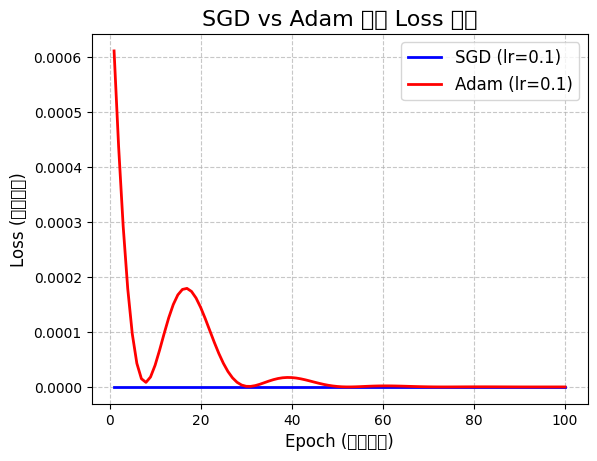

In [50]:
plt.plot(epochs, loss_history_sgd, label=f'SGD (lr={lr_sgd})', color='blue', linewidth=2)
plt.plot(epochs, loss_history_adam, label=f'Adam (lr={lr_adam})', color='red', linewidth=2)

plt.title('SGD vs Adam 训练 Loss 对比', fontsize=16)
plt.xlabel('Epoch (训练轮数)', fontsize=12)
plt.ylabel('Loss (均方误差)', fontsize=12)

plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()